# Step 1: Exploratory Data Analysis & Regression Assumptions
**Project:** London Housing Price Prediction & Market Trends
**Goals:**
1. Inspect dataset structure, data types, missingness, and summary statistics.
2. Explore distributions of the target variable (`price`) and key physical features.
3. Check initial linear regression assumptions (linearity, multicollinearity, feature correlations).

In [10]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Plot styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

# Resolve path relative to project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = (
    PROJECT_ROOT / "data" / "processed" / "cleaned_london_house_prices.csv"
)

df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape[0]:,} rows | {df.shape[1]} columns")

Dataset shape: 417,436 rows | 24 columns


In [11]:
# Inspect columns, non-null counts, and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 417436 entries, 0 to 417435
Data columns (total 24 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   fullAddress               417436 non-null  str    
 1   postcode                  417436 non-null  str    
 2   country                   417436 non-null  str    
 3   outcode                   417436 non-null  str    
 4   latitude                  417436 non-null  float64
 5   longitude                 417436 non-null  float64
 6   bathrooms                 339736 non-null  float64
 7   bedrooms                  377090 non-null  float64
 8   floorAreaSqM              392398 non-null  float64
 9   livingRooms               357131 non-null  float64
 10  tenure                    405951 non-null  str    
 11  propertyType              416310 non-null  str    
 12  currentEnergyRating       333177 non-null  str    
 13  saleEstimate_lowerPrice   417436 non-null  float64
 14 

In [12]:
# Check missing values per column
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame(
    {"missing_count": missing, "percentage": missing_pct}
)
missing_df[missing_df["missing_count"] > 0].sort_values(
    by="missing_count", ascending=False
)

,missing_count,percentage
history_percentageChange,179873,43.089959
history_numericChange,179873,43.089959
currentEnergyRating,84259,20.184891
bathrooms,77700,18.613632
livingRooms,60305,14.446526
bedrooms,40346,9.665194
floorAreaSqM,25038,5.998045
tenure,11485,2.751320
propertyType,1126,0.269742


In [13]:
# Numerical summary stats
df[
    [
        "price",
        "floorAreaSqM",
        "bedrooms",
        "bathrooms",
        "livingRooms",
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
price,417436.0,902331.511896,896582.089726,89000.0,446000.0,622000.0,983000.0,14963000.0
floorAreaSqM,392398.0,98.890759,55.837389,15.0,63.0,84.0,116.0,500.0
bedrooms,377090.0,2.474033,1.159439,1.0,2.0,2.0,3.0,9.0
bathrooms,339736.0,1.443845,0.723353,1.0,1.0,1.0,2.0,9.0
livingRooms,357131.0,1.281703,0.573259,1.0,1.0,1.0,1.0,9.0


## Step 2: Distribution of the Target Variable (`price`)
Linear regression assumes that relationships are linear and errors are normally distributed. House prices are typically heavily right-skewed, so inspecting both raw prices and $\log(\text{price})$ is essential.

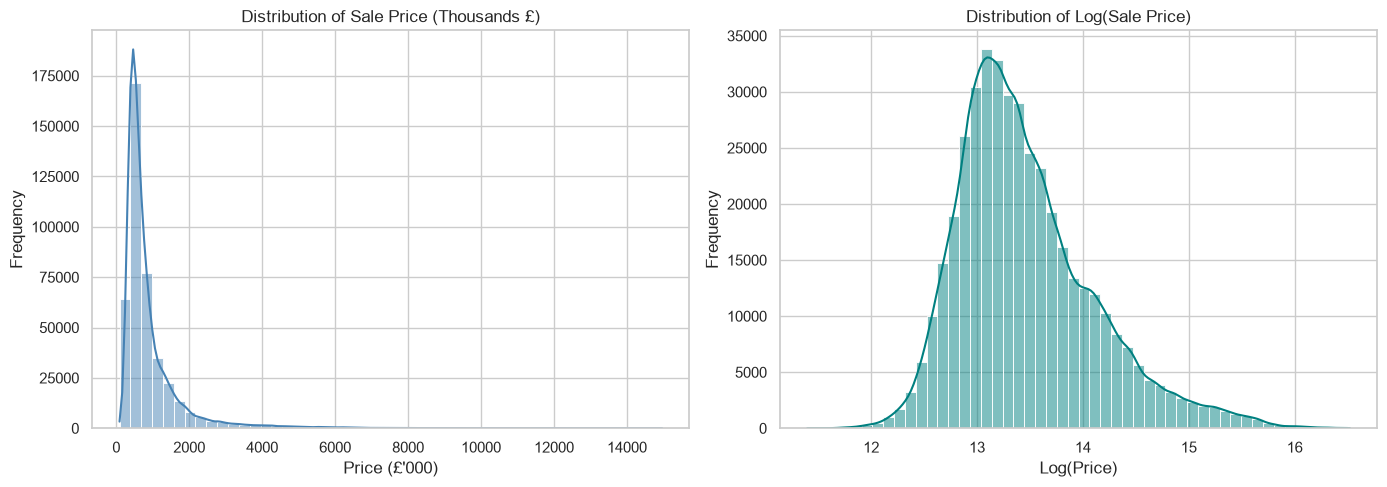

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw Price Distribution
sns.histplot(
    df["price"] / 1_000, bins=50, kde=True, ax=axes[0], color="steelblue"
)
axes[0].set_title("Distribution of Sale Price (Thousands £)")
axes[0].set_xlabel("Price (£'000)")
axes[0].set_ylabel("Frequency")

# Log-Transformed Price Distribution
sns.histplot(
    np.log1p(df["price"]), bins=50, kde=True, ax=axes[1], color="teal"
)
axes[1].set_title("Distribution of Log(Sale Price)")
axes[1].set_xlabel("Log(Price)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## Step 3: Categorical Features vs. Price
Let's examine how prices vary by `propertyType` and `tenure`.

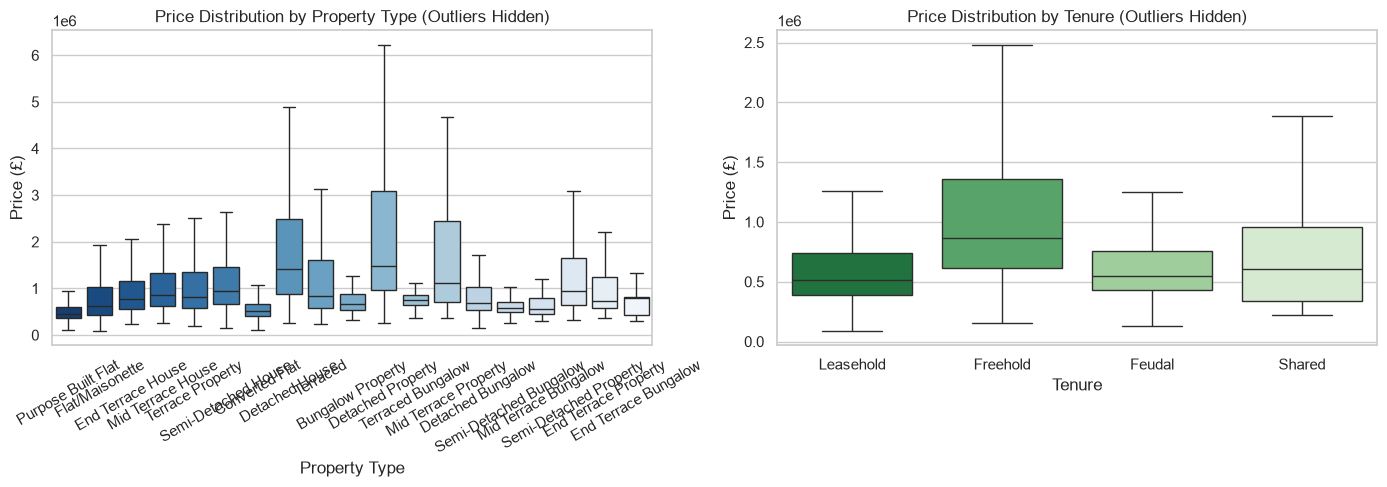

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Price by Property Type
sns.boxplot(
    data=df,
    x="propertyType",
    y="price",
    hue="propertyType",
    legend=False,
    showfliers=False,
    ax=axes[0],
    palette="Blues_r",
)

axes[0].set_title("Price Distribution by Property Type (Outliers Hidden)")
axes[0].set_xlabel("Property Type")
axes[0].set_ylabel("Price (£)")
axes[0].tick_params(axis="x", rotation=30)

# Price by Tenure
if "tenure" in df.columns:
    sns.boxplot(
        data=df,
        x="tenure",
        y="price",
        hue="tenure",
        legend=False,
        showfliers=False,
        ax=axes[1],
        palette="Greens_r",
    )

    axes[1].set_title("Price Distribution by Tenure (Outliers Hidden)")
    axes[1].set_xlabel("Tenure")
    axes[1].set_ylabel("Price (£)")

else:
    axes[1].set_visible(False)

plt.tight_layout()
plt.show()

## Step 4: Check Initial Regression Assumptions

1. **Linearity:** Plot numeric features (`floorAreaSqM`, `bedrooms`, `bathrooms`) against `price`.
2. **Multicollinearity:** Examine correlations among continuous predictor variables.

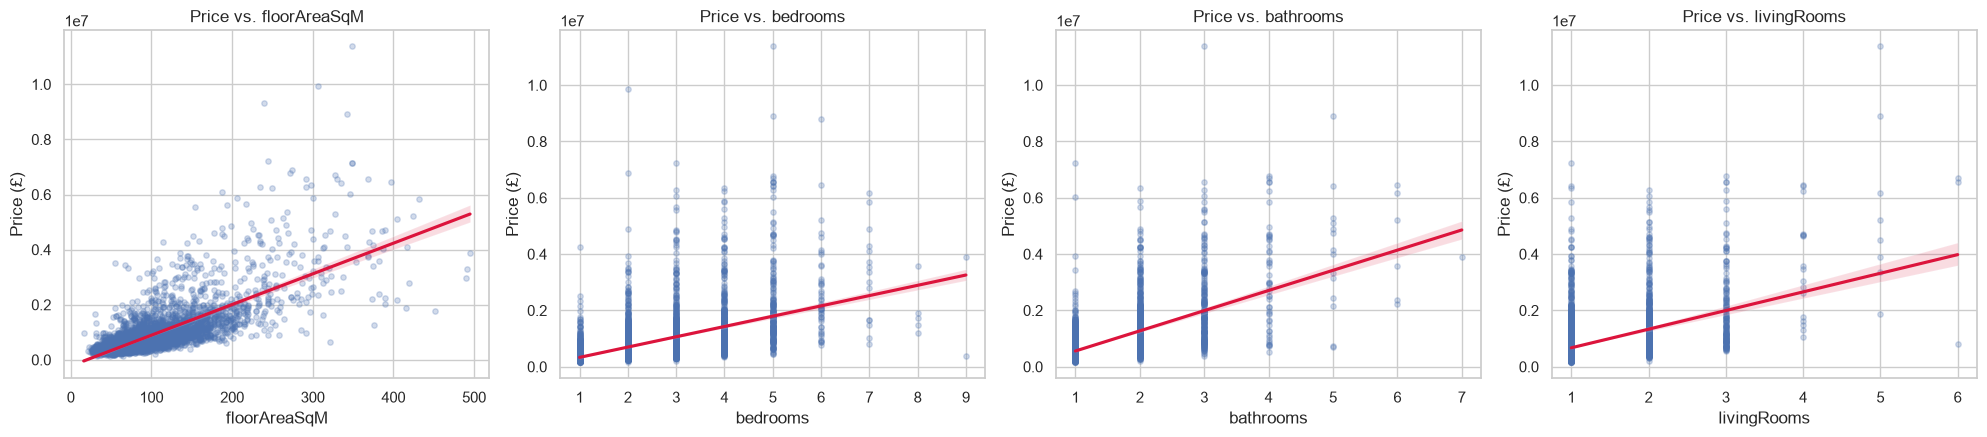

In [17]:
numeric_preds = [
    c
    for c in ["floorAreaSqM", "bedrooms", "bathrooms", "livingRooms"]
    if c in df.columns
]

# Take a random sample of 5,000 rows for responsive, legible plotting
sample_df = df.sample(n=min(5000, len(df)), random_state=42)

fig, axes = plt.subplots(1, len(numeric_preds), figsize=(5 * len(numeric_preds), 4.5))

for idx, col in enumerate(numeric_preds):
    sns.regplot(
        data=sample_df,
        x=col,
        y="price",
        scatter_kws={"alpha": 0.25, "s": 15},
        line_kws={"color": "crimson"},
        ax=axes[idx],
    )
    axes[idx].set_title(f"Price vs. {col}")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Price (£)")

plt.tight_layout()
plt.show()

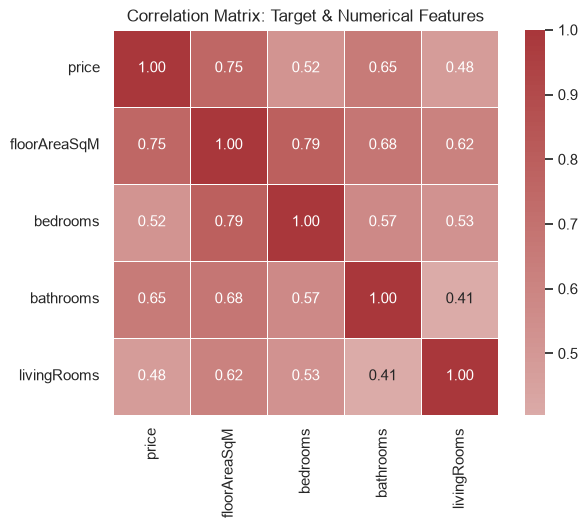

In [18]:
corr_features = ["price"] + numeric_preds
corr_matrix = df[corr_features].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    square=True,
    linewidths=0.5,
)
plt.title("Correlation Matrix: Target & Numerical Features")
plt.show()

### Key Takeaways for Modeling: